## 1. Imports, paths and experiment settings

In [1]:
from pathlib import Path
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebook is expected inside: project/notebooks/
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "phase4_final":
    PROJECT_DIR = PROJECT_DIR.parent
elif not (PROJECT_DIR / "embeddings").exists() and (PROJECT_DIR.parent / "embeddings").exists():
    PROJECT_DIR = PROJECT_DIR.parent

EMBEDDINGS_DIR = PROJECT_DIR / "embeddings"
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "phase4"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Available data: 1k, 3k, 6k, 12k.
# We derive 5k and 10k as prefixes of the existing 12k embedding matrix.
EXPERIMENT_SIZES = [1000, 5000, 10000, 12000]
K = 5
WARMUP = 2
RUNS = 5
RANDOM_SEED = 42

print("Project:", PROJECT_DIR)
print("Embedding directory exists:", EMBEDDINGS_DIR.exists())
print("Results:", RESULTS_DIR)


Project: c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine
Embedding directory exists: True
Results: c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine\results\phase4


## 2. Load the existing 12K embeddings and metadata

In [2]:
BASE_DIR = EMBEDDINGS_DIR / "12k"

required_files = [
    BASE_DIR / "corpus_embeddings.npy",
    BASE_DIR / "corpus_metadata.csv",
    BASE_DIR / "query_embeddings.npy",
    BASE_DIR / "query_metadata.csv",
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(
        "12K embedding files were not found. Check PROJECT_DIR and folder names:\n"
        + "\n".join(missing)
    )

corpus_raw = np.load(BASE_DIR / "corpus_embeddings.npy")
queries_raw = np.load(BASE_DIR / "query_embeddings.npy")
corpus_metadata_12k = pd.read_csv(BASE_DIR / "corpus_metadata.csv")
query_metadata = pd.read_csv(BASE_DIR / "query_metadata.csv")

print("Corpus embeddings:", corpus_raw.shape, corpus_raw.dtype)
print("Query embeddings:", queries_raw.shape, queries_raw.dtype)
print("Corpus metadata:", corpus_metadata_12k.shape)
print("Query metadata:", query_metadata.shape)

assert corpus_raw.ndim == 2 and queries_raw.ndim == 2
assert corpus_raw.shape[1] == queries_raw.shape[1]
assert len(corpus_metadata_12k) >= len(corpus_raw)
assert len(query_metadata) == len(queries_raw)
assert len(corpus_raw) >= max(EXPERIMENT_SIZES)


Corpus embeddings: (12000, 384) float32
Query embeddings: (50, 384) float32
Corpus metadata: (12000, 1)
Query metadata: (50, 3)


## 3. Prepare cosine similarity vectors

Cosine similarity is calculated as a dot product after L2 normalization. Normalization is applied in memory only; the original `.npy` files remain unchanged.

In [3]:
def l2_normalize(matrix: np.ndarray) -> np.ndarray:
    matrix = np.asarray(matrix, dtype=np.float32)
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    # Keep zero vectors safe (they remain zero).
    norms[norms == 0] = 1.0
    return matrix / norms

corpus_all = l2_normalize(corpus_raw)
queries = l2_normalize(queries_raw)

print("Normalized corpus:", corpus_all.shape)
print("Normalized queries:", queries.shape)
print("Corpus norm range:",
      float(np.linalg.norm(corpus_all, axis=1).min()),
      "to",
      float(np.linalg.norm(corpus_all, axis=1).max()))


Normalized corpus: (12000, 384)
Normalized queries: (50, 384)


Corpus norm range: 0.9999998807907104 to 1.0000001192092896


## 4. Final vectorized search implementation

In [4]:
def search_numpy(query_matrix: np.ndarray,
                 corpus_matrix: np.ndarray,
                 k: int = 5):
    # \"\"\"Return per-query top-k (document_index, cosine_score) pairs.\"\"\"
    if k < 1:
        raise ValueError("k must be >= 1")
    k = min(k, len(corpus_matrix))

    # BLAS-backed matrix multiplication; all vectors are already normalized.
    similarities = query_matrix @ corpus_matrix.T

    # Partial selection, then sort only the selected candidates.
    candidate_idx = np.argpartition(-similarities, kth=k-1, axis=1)[:, :k]
    candidate_scores = np.take_along_axis(similarities, candidate_idx, axis=1)
    order = np.argsort(-candidate_scores, axis=1)
    top_idx = np.take_along_axis(candidate_idx, order, axis=1)
    top_scores = np.take_along_axis(candidate_scores, order, axis=1)

    return [
        [(int(idx), float(score)) for idx, score in zip(row_i, row_s)]
        for row_i, row_s in zip(top_idx, top_scores)
    ]

# Quick smoke test
quick_results = search_numpy(queries[:2], corpus_all[:1000], k=K)
quick_results[0][:K]


[(93, 0.7286847829818726),
 (108, 0.701743483543396),
 (642, 0.6829954385757446),
 (454, 0.6734638810157776),
 (910, 0.6680681109428406)]

## 5. Dimensionality-reduction decision

Phase 2 evaluated SVD methods on a separate matrix. For this final system, we preserve the original 384-dimensional embeddings unless a reduced representation can retain the same top-k results. The following optional experiment measures retrieval agreement after TruncatedSVD. It is a diagnostic only; the final benchmark below uses the full 384 dimensions.

In [5]:
# Optional SVD experiment. Set RUN_SVD_CHECK=False to skip.
RUN_SVD_CHECK = True
SVD_COMPONENTS = [256, 128]

if RUN_SVD_CHECK:
    try:
        from sklearn.decomposition import TruncatedSVD

        # Use a reproducible subset to keep the diagnostic lightweight.
        sample_n = min(3000, len(corpus_all))
        sample_corpus = corpus_all[:sample_n]
        sample_queries = queries[:min(20, len(queries))]
        full_topk = search_numpy(sample_queries, sample_corpus, k=K)

        svd_rows = []
        for n_components in SVD_COMPONENTS:
            if n_components >= sample_corpus.shape[1]:
                continue
            reducer = TruncatedSVD(n_components=n_components, random_state=RANDOM_SEED)
            reduced_corpus = l2_normalize(reducer.fit_transform(sample_corpus))
            reduced_queries = l2_normalize(reducer.transform(sample_queries))
            reduced_topk = search_numpy(reduced_queries, reduced_corpus, k=K)

            agreements = []
            for full_row, reduced_row in zip(full_topk, reduced_topk):
                full_ids = {idx for idx, _ in full_row}
                reduced_ids = {idx for idx, _ in reduced_row}
                agreements.append(len(full_ids & reduced_ids) / K)

            svd_rows.append({
                "dimensions": n_components,
                "top5_overlap": float(np.mean(agreements)),
                "exact_top5_match_rate": float(np.mean([
                    [i for i, _ in a] == [i for i, _ in b]
                    for a, b in zip(full_topk, reduced_topk)
                ]))
            })

        svd_results = pd.DataFrame(svd_rows)
        display(svd_results)
    except ImportError:
        print("scikit-learn is not installed; skipping optional SVD diagnostic.")
else:
    print("SVD diagnostic skipped.")

print("Final system retains the original 384 dimensions to preserve baseline retrieval ranking.")


,dimensions,top5_overlap,exact_top5_match_rate
0,256,0.97,0.55
1,128,0.89,0.10


Final system retains the original 384 dimensions to preserve baseline retrieval ranking.


## 6. Scaling benchmark: 1K, 5K, 10K, 12K

All corpus sizes use prefixes of the same 12K ordering and the same query set. This keeps the scaling comparison controlled. The benchmark includes similarity calculation and top-k selection, but excludes file loading and normalization.

In [6]:
def benchmark_search(query_matrix, corpus_matrix,
                     warmup=3, runs=7, repeat=20):

    def run_repeated():
        for _ in range(repeat):
            search_numpy(query_matrix, corpus_matrix, k=K)

    for _ in range(warmup):
        run_repeated()

    elapsed = []

    for _ in range(runs):
        start = time.perf_counter()
        run_repeated()
        elapsed.append((time.perf_counter() - start) / repeat)

    return {
        "mean_seconds": float(np.mean(elapsed)),
        "median_seconds": float(np.median(elapsed)),
        "std_seconds": float(np.std(elapsed)),
        "min_seconds": float(np.min(elapsed)),
        "max_seconds": float(np.max(elapsed)),
        "time_per_query_ms": float(
            np.mean(elapsed) / len(query_matrix) * 1000
        )
    }

scaling_rows = []
for size in EXPERIMENT_SIZES:
    corpus_size = corpus_all[:size]
    metrics = benchmark_search(queries, corpus_size)
    scaling_rows.append({
        "corpus_size": size,
        "num_queries": len(queries),
        "dimensions": corpus_size.shape[1],
        **metrics,
    })
    print(f"{size:>5,} docs | {metrics['mean_seconds']:.6f}s "
          f"+/- {metrics['std_seconds']:.6f}s")

scaling_df = pd.DataFrame(scaling_rows)
display(scaling_df)
scaling_csv = RESULTS_DIR / "phase4_scaling_results.csv"
scaling_df.to_csv(scaling_csv, index=False)
print("Saved:", scaling_csv)


1,000 docs | 0.005739s +/- 0.006609s
5,000 docs | 0.011894s +/- 0.006714s
10,000 docs | 0.014264s +/- 0.005324s
12,000 docs | 0.014610s +/- 0.004948s


,corpus_size,num_queries,dimensions,mean_seconds,median_seconds,std_seconds,min_seconds,max_seconds,time_per_query_ms
0,1000,50,384,0.005739,0.001537,0.006609,0.001000,0.019133,0.114786
1,5000,50,384,0.011894,0.010052,0.006714,0.004051,0.023006,0.237876
2,10000,50,384,0.014264,0.012840,0.005324,0.008671,0.026571,0.285276
3,12000,50,384,0.014610,0.012503,0.004948,0.011063,0.026369,0.292204


Saved: c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine\results\phase4\phase4_scaling_results.csv


## 7. Scaling curve and growth analysis

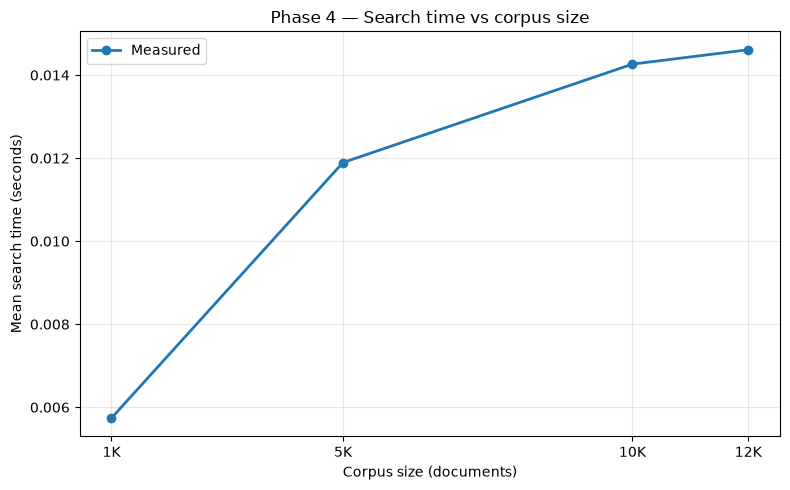

Saved: c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine\results\phase4\phase4_scaling_curve.png


,corpus_size,mean_seconds,corpus_growth_factor,time_growth_factor,time_per_document_us
0,1000,0.005739,1.0,1.000000,5.739321
1,5000,0.011894,5.0,2.072336,2.378760
2,10000,0.014264,10.0,2.485276,1.426379
3,12000,0.014610,12.0,2.545632,1.217517


In [7]:
plt.figure(figsize=(8, 5))
plt.plot(scaling_df["corpus_size"], scaling_df["mean_seconds"],
         marker="o", linewidth=2, label="Measured")
plt.xlabel("Corpus size (documents)")
plt.ylabel("Mean search time (seconds)")
plt.title("Phase 4 — Search time vs corpus size")
plt.grid(True, alpha=0.3)
plt.xticks(scaling_df["corpus_size"], [f"{x//1000}K" for x in scaling_df["corpus_size"]])
plt.legend()
plt.tight_layout()
scaling_plot = RESULTS_DIR / "phase4_scaling_curve.png"
plt.savefig(scaling_plot, dpi=160)
plt.show()
print("Saved:", scaling_plot)

# Compare measured time growth with corpus-size growth relative to 1K.
base_time = scaling_df.iloc[0]["mean_seconds"]
base_size = scaling_df.iloc[0]["corpus_size"]
growth_df = scaling_df[["corpus_size", "mean_seconds"]].copy()
growth_df["corpus_growth_factor"] = growth_df["corpus_size"] / base_size
growth_df["time_growth_factor"] = growth_df["mean_seconds"] / base_time
growth_df["time_per_document_us"] = (
    growth_df["mean_seconds"] / growth_df["corpus_size"] * 1_000_000
)
display(growth_df)


## 8. Correctness check against the Phase 1 pure-Python baseline

This reproduces the Phase 1 `cosine_similarity_python` and `search_naive` logic. We compare top-5 document indices and cosine scores. Score tolerance is `1e-5`. The Python baseline is intentionally slow; run this cell once after the scaling benchmark.

In [8]:
def cosine_similarity_python(a, b):
    dot_product = 0.0
    sum_a_squared = 0.0
    sum_b_squared = 0.0

    for i in range(len(a)):
        dot_product += float(a[i]) * float(b[i])
        sum_a_squared += float(a[i]) * float(a[i])
        sum_b_squared += float(b[i]) * float(b[i])

    norm_a = math.sqrt(sum_a_squared)
    norm_b = math.sqrt(sum_b_squared)
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot_product / (norm_a * norm_b)


def search_naive(queries_list, corpus_list, k=5):
    results = []
    for query in queries_list:
        scores = []
        for doc_index, doc in enumerate(corpus_list):
            score = cosine_similarity_python(query, doc)
            scores.append((doc_index, score))
        scores.sort(key=lambda item: item[1], reverse=True)
        results.append(scores[:k])
    return results


def verify_against_baseline(size, tolerance=1e-5):
    # Use original vectors: baseline computes cosine explicitly.
    corpus = corpus_raw[:size]
    query_vectors = queries_raw

    t0 = time.perf_counter()
    baseline_results = search_naive(query_vectors.tolist(), corpus.tolist(), k=K)
    baseline_seconds = time.perf_counter() - t0

    optimized_results = search_numpy(queries, corpus_all[:size], k=K)

    index_matches = 0
    score_checks = 0
    max_abs_score_error = 0.0

    for baseline_row, optimized_row in zip(baseline_results, optimized_results):
        baseline_indices = [idx for idx, _ in baseline_row]
        optimized_indices = [idx for idx, _ in optimized_row]
        if baseline_indices == optimized_indices:
            index_matches += 1

        for (base_idx, base_score), (opt_idx, opt_score) in zip(baseline_row, optimized_row):
            if base_idx == opt_idx:
                err = abs(base_score - opt_score)
                max_abs_score_error = max(max_abs_score_error, err)
                if err <= tolerance:
                    score_checks += 1

    total_queries = len(baseline_results)
    total_scores = total_queries * K
    passed = (index_matches == total_queries and score_checks == total_scores)

    return {
        "corpus_size": size,
        "queries": total_queries,
        "top5_exact_match_queries": index_matches,
        "top5_match_rate": index_matches / total_queries,
        "score_checks_passed": score_checks,
        "total_score_checks": total_scores,
        "max_abs_score_error": max_abs_score_error,
        "tolerance": tolerance,
        "baseline_seconds": baseline_seconds,
        "correctness": "PASS" if passed else "FAIL",
    }

correctness_rows = []
for size in EXPERIMENT_SIZES:
    result = verify_against_baseline(size)
    correctness_rows.append(result)
    print(f"{size:>5,} docs: {result['correctness']} | "
          f"top-5 exact {result['top5_exact_match_queries']}/{result['queries']} | "
          f"max score error {result['max_abs_score_error']:.2e} | "
          f"baseline {result['baseline_seconds']:.2f}s")

correctness_df = pd.DataFrame(correctness_rows)
display(correctness_df)
correctness_csv = RESULTS_DIR / "phase4_correctness_results.csv"
correctness_df.to_csv(correctness_csv, index=False)
print("Saved:", correctness_csv)


1,000 docs: PASS | top-5 exact 50/50 | max score error 2.18e-07 | baseline 4.71s
5,000 docs: PASS | top-5 exact 50/50 | max score error 2.09e-07 | baseline 24.84s
10,000 docs: PASS | top-5 exact 50/50 | max score error 2.44e-07 | baseline 49.94s
12,000 docs: PASS | top-5 exact 50/50 | max score error 2.44e-07 | baseline 61.83s


,corpus_size,queries,top5_exact_match_queries,top5_match_rate,score_checks_passed,total_score_checks,max_abs_score_error,tolerance,baseline_seconds,correctness
0,1000,50,50,1.0,250,250,2.181457e-07,0.00001,4.705485,PASS
1,5000,50,50,1.0,250,250,2.086704e-07,0.00001,24.844993,PASS
2,10000,50,50,1.0,250,250,2.437443e-07,0.00001,49.943840,PASS
3,12000,50,50,1.0,250,250,2.437443e-07,0.00001,61.825526,PASS


Saved: c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine\results\phase4\phase4_correctness_results.csv


## 9. Compare optimized search with the recorded Phase 1 baseline

The report's Phase 1 baseline is **28.394 seconds** (an earlier recorded run). The later `baseline.txt` measurement, **29.237241 seconds**, belongs to a different run. Keep them separate; do not overwrite the report value. This comparison uses the report's recorded value and the 12K Phase 4 measurement.

In [9]:
PHASE1_REPORT_BASELINE_SECONDS = 28.394  # Earlier run recorded in the report.
PHASE1_LATER_BASELINE_SECONDS = 29.237241  # Separate later run from baseline.txt.

phase4_12k_time = float(
    scaling_df.loc[scaling_df["corpus_size"] == 12000, "mean_seconds"].iloc[0]
)

comparison_df = pd.DataFrame([
    {"version": "Phase 1 baseline (report, earlier run)",
     "time_seconds": PHASE1_REPORT_BASELINE_SECONDS},
    {"version": "Phase 1 baseline.txt (later separate run)",
     "time_seconds": PHASE1_LATER_BASELINE_SECONDS},
    {"version": "Phase 4 NumPy (12K, measured now)",
     "time_seconds": phase4_12k_time},
])
comparison_df["speedup_vs_report_baseline"] = (
    PHASE1_REPORT_BASELINE_SECONDS / comparison_df["time_seconds"]
)
display(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "phase4_baseline_comparison.csv", index=False)


,version,time_seconds,speedup_vs_report_baseline
0,"Phase 1 baseline (report, earlier run)",28.394000,1.000000
1,Phase 1 baseline.txt (later separate run),29.237241,0.971159
2,"Phase 4 NumPy (12K, measured now)",0.014610,1943.436967


## 10. Live Demo — Searching the 12K Document Collection
In this section, the user is prompted to enter a free-text query. The SentenceTransformer model generates an embedding only for the new query, while the precomputed embeddings of the 12K-document corpus are reused. The final NumPy-based search function then retrieves the five most similar documents.

Note: If the model has not been downloaded previously, its files will be downloaded during the first run. An internet connection and the sentence-transformers package are required. For subsequent queries, the model remains loaded in memory and does not need to be loaded again.

In [10]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

# Load the query encoder once. The corpus embeddings are NOT regenerated.
if "query_encoder" not in globals():
    print("Loading sentence-transformer model on CPU...")
    query_encoder = SentenceTransformer(MODEL_NAME, device="cpu")
    print("Model is ready.")

user_query = input("Enter your search query: ").strip()

if not user_query:
    print("Please enter a non-empty query.")
else:
    # Encode only the new query.
    query_vector = query_encoder.encode(
        [user_query],
        convert_to_numpy=True,
        show_progress_bar=False
    ).astype(np.float32)

    query_vector = l2_normalize(query_vector)

    # Search against the already-loaded 12K corpus vectors.
    live_results = search_numpy(query_vector, corpus_all, k=K)[0]

    print(f"\nTop-{len(live_results)} results for: {user_query}\n")

    # Display the metadata associated with each retrieved document.
    result_rows = []
    for rank, (doc_idx, score) in enumerate(live_results, start=1):
        metadata_row = corpus_metadata_12k.iloc[doc_idx].to_dict()
        metadata_row["rank"] = rank
        metadata_row["cosine_similarity"] = round(score, 6)
        result_rows.append(metadata_row)

    results_df = pd.DataFrame(result_rows)
    preferred_columns = ["rank", "doc_id", "cosine_similarity"]
    display_columns = [c for c in preferred_columns if c in results_df.columns]
    display_columns += [c for c in results_df.columns if c not in display_columns]
    display(results_df[display_columns])

    # If the metadata does not contain document text, try loading it from the source CSV.
    text_columns = ["text", "document", "content", "document_text"]
    available_text_column = next(
        (c for c in text_columns if c in corpus_metadata_12k.columns),
        None
    )

    documents_df = pd.read_csv(
        DATA_DIR / "synthetic_documents_12000_1b_v2.csv"
    )

    documents_df = documents_df.set_index("doc_id")

    print("\nRetrieved documents:\n")

    for rank, (doc_idx, score) in enumerate(live_results, start=1):
        doc_id = corpus_metadata_12k.iloc[doc_idx]["doc_id"]
        document = documents_df.loc[doc_id]

        print(f"\n{'='*80}")
        print(f"Rank: {rank} | Document: {doc_id}")
        print(f"Cosine Similarity: {score:.5f}")
        print(f"Topic: {document['topic']}")
        print(f"{'='*80}")
        print(document["text"])


c:\Users\dgnme\OneDrive\Masaüstü\269797012- Similarity Search Engine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading sentence-transformer model on CPU...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2233.23it/s]


Model is ready.

Top-5 results for: How can we prevent cybersecurity threats?



,rank,doc_id,cosine_similarity
0,1,doc_01282,0.703295
1,2,doc_02877,0.700998
2,3,doc_04179,0.697954
3,4,doc_03173,0.690518
4,5,doc_09274,0.688718



Retrieved documents:


Rank: 1 | Document: doc_01282
Cosine Similarity: 0.70330
Topic: cybersecurity
Cybersecurity is a crucial aspect of modern life, protecting individuals and organizations from cyber threats. It involves safeguarding sensitive data and preventing unauthorized access, thereby safeguarding personal and financial information. Effective cybersecurity measures, such as encryption and firewalls, can prevent hackers from breaching secure systems. For instance, a recent example is the WannaCry ransomware attack, which targeted the UK healthcare system, resulting in significant financial losses and a major disruption to patient care.

Rank: 2 | Document: doc_02877
Cosine Similarity: 0.70100
Topic: cybersecurity
Cybersecurity is a critical aspect of modern life, affecting not only individuals but also organizations. As technology advances, the risk of cyber attacks increases, compromising sensitive data and disrupting operations. Individuals can protect themselves through aw